# Get Data

In [54]:
from strategies import *
import pickle

currency = "BTCUSDT"
start_time = "2022-01-01"
stop_time = "2023-01-01"
timeframe = "4h"
src_name = f"{currency}_{start_time}_{stop_time}_{timeframe}"

try:
    with open(f"{src_name}.pkl", "rb") as f:
        src = pickle.load(f)
        print("📂 Loaded data from file.")
except:
    src = ConnectBinance(currency=currency, start_time=start_time, stop_time=stop_time, timeframe=timeframe)
    if src._ready:
        try:
            with open(f"{src_name}.pkl", "wb") as f:
                pickle.dump(src, f)
            print("💾 Data saved to file.")
            
        except:
            print("❌ERROR: could not open the file")


🔄️ Downloading Data from Binance ...
✅ Data downloaded from Binance successfully.
💾 Data saved to file.


# 1- Moving Average Strategy

✨ Start Trading ....
✅ Trading Finished Successfully.
===================  Final Backtest Result of Simple Moving Average Strategy ===================
❇️ Initial Capital: 1000.00 USD
❇️ Final Capital: 991.37 USD
❇️ Profit-Loss: -8.63 USD
❇️ Total Return: -0.86 %
❇️ Total Trades: 48 (Winning: 17 | Losing: 31)
❇️ Win-Rate: 35.42 %


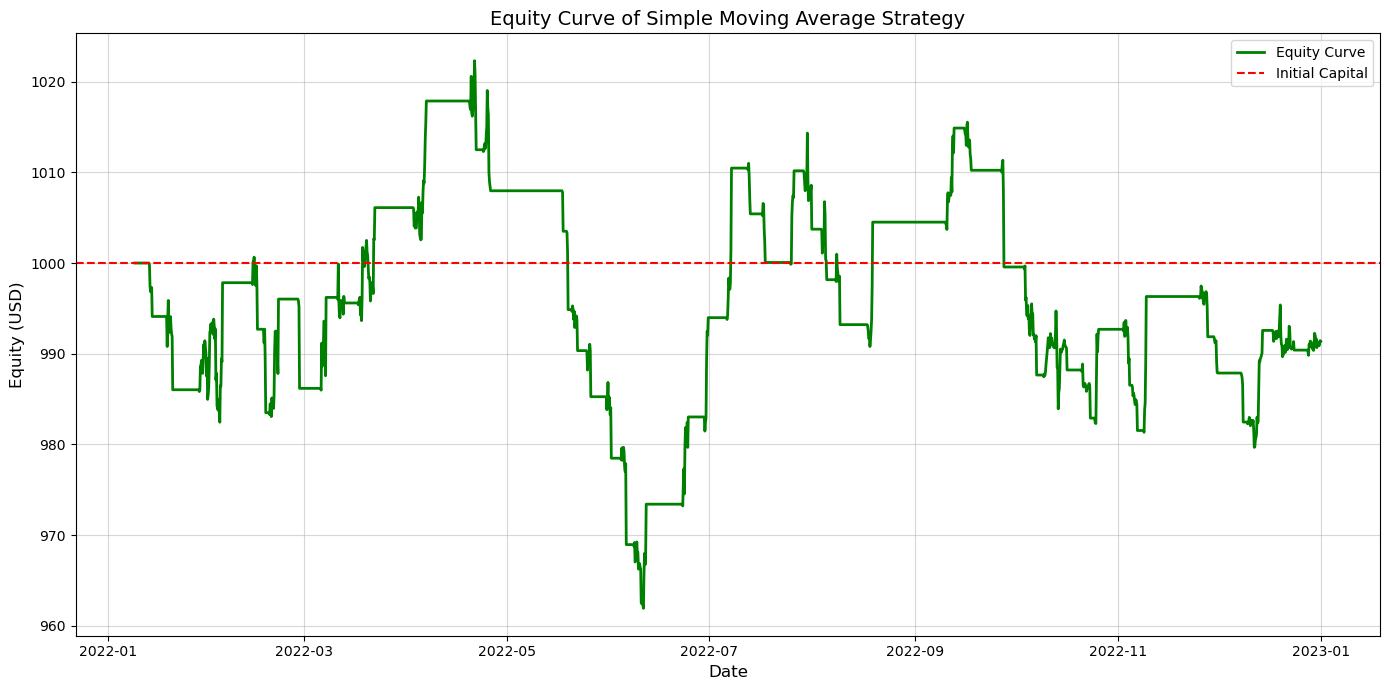

In [55]:
mavg_strategy = MovingAverage(src)
windows = {"Close": [20, 50]}
mavg_strategy.add_sma(windows)
mavg_strategy.trade(price="Close", windows=(20, 50), margin_portion=0.2)
mavg_strategy.report()

In [3]:
mavg_strategy.trades_info

,position-type,entry-date,entry-price,exit-date,exit-price,reason,trade-return,account-impact
0,short,2022-01-03 03:00:00,46793.26,2022-01-05 20:00:00,43967.01,Meeting Profit Level,5.845905,1.169181
1,long,2022-01-09 16:00:00,42143.04,2022-01-10 12:00:00,40930.00,Meeting Loss Level,-3.075509,-0.622293
2,short,2022-01-10 17:00:00,41184.45,2022-01-11 02:00:00,42173.77,Meeting Loss Level,-2.604571,-0.523763
3,long,2022-01-11 10:00:00,41631.02,2022-01-12 13:00:00,43920.97,Meeting Profit Level,5.295085,1.059262
4,short,2022-01-14 01:00:00,42581.12,2022-01-15 08:00:00,42983.95,Crossover in average lines,-1.146976,-0.231878
...,...,...,...,...,...,...,...,...
135,long,2022-12-20 15:00:00,16918.83,2022-12-22 03:00:00,16852.80,Inverse-Crossover in average lines,-0.589885,-0.112675
136,long,2022-12-23 13:00:00,16841.76,2022-12-25 16:00:00,16815.96,Inverse-Crossover in average lines,-0.353037,-0.067355
137,long,2022-12-26 09:00:00,16832.98,2022-12-27 18:00:00,16636.46,Inverse-Crossover in average lines,-1.366303,-0.260489
138,long,2022-12-30 04:00:00,16613.79,2022-12-30 08:00:00,16500.24,Inverse-Crossover in average lines,-0.882785,-0.167845


In [4]:
mavg_strategy.statistics

{'initial-capital': 1000,
 'capital': 947.9490528385923,
 'tp': 0.05,
 'sl': 0.02,
 'commission-rate': 0.001,
 'commission-paid': 54.82243360379008,
 'win-rate': 29.28571428571429,
 'total-trade': 140,
 'winning-trade': 41,
 'losing-trade': 99,
 'breakeven-trade': 0,
 'total-return': -5.205094716140775,
 'crossover': 'Close 20-50'}

# 2- Bollinger Band Strategy

✨ Start Trading ....
✅ Trading Finished Successfully.
===================  Final Backtest Result of Bollinger Band Strategy ===================
❇️ Initial Capital: 1000.00 USD
❇️ Final Capital: 840.26 USD
❇️ Profit-Loss: -159.74 USD
❇️ Total Return: -15.97 %
❇️ Total Trades: 112 (Winning: 44 | Losing: 68)
❇️ Win-Rate: 39.29 %


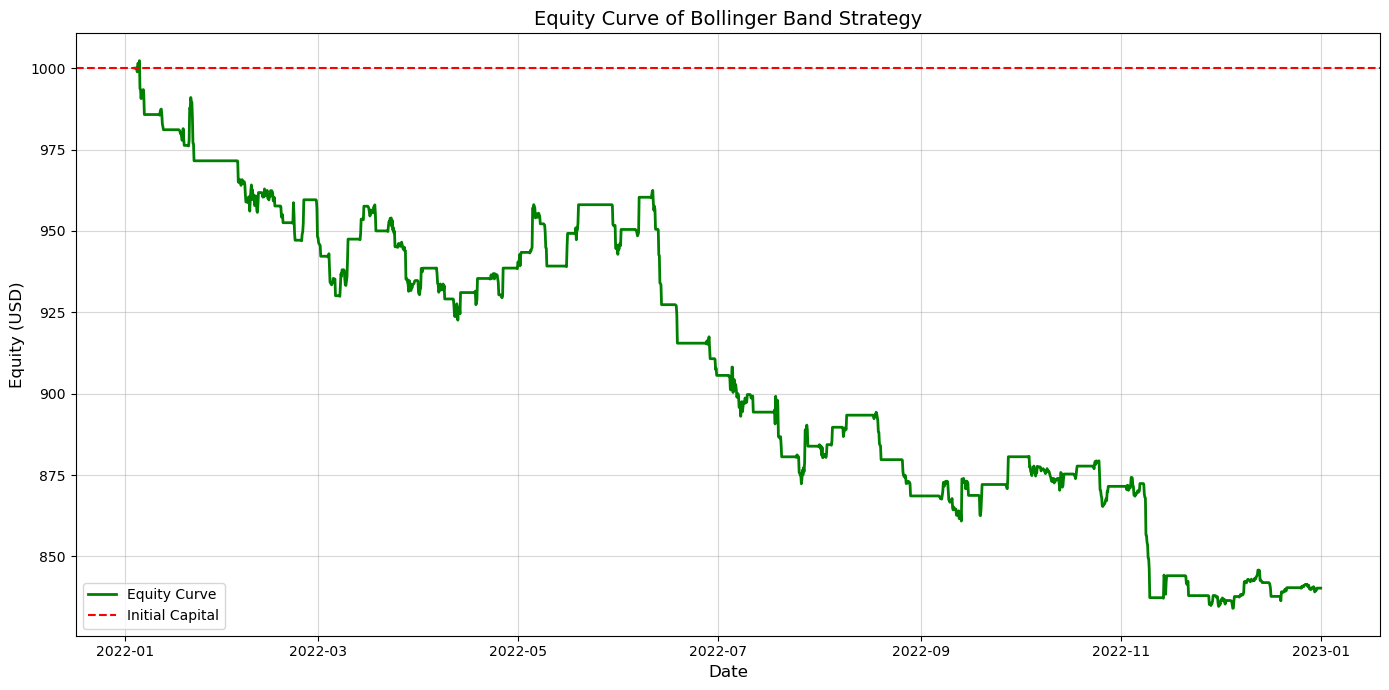

In [56]:
bb_strategy = BollingerBand(src)
price = "Close"
bb_strategy.add_bands(price=price, window=20)
bb_strategy.trade(price=price, window=20, margin_portion=0.2)
bb_strategy.report()

In [6]:
bb_strategy.trades_info

,position-type,entry-date,entry-price,exit-date,exit-price,reason,trade-return,account-impact
0,short,2022-01-02 16:00:00,47792.30,2022-01-02 18:00:00,47058.12,Downward Mean Reversion,1.337725,0.267545
1,long,2022-01-03 15:00:00,46693.45,2022-01-04 07:00:00,46550.00,Upward Mean Reversion,-0.506909,-0.101653
2,short,2022-01-04 13:00:00,46955.22,2022-01-04 18:00:00,45750.00,Downward Mean Reversion,2.369310,0.474648
3,long,2022-01-05 19:00:00,44685.93,2022-01-05 21:00:00,43606.37,Meeting Loss Level,-2.613468,-0.526042
4,long,2022-01-05 22:00:00,43437.05,2022-01-06 18:00:00,43369.04,Upward Mean Reversion,-0.356415,-0.071365
...,...,...,...,...,...,...,...,...
401,long,2022-12-27 14:00:00,16772.25,2022-12-28 11:00:00,16678.98,Upward Mean Reversion,-0.755541,-0.121663
402,short,2022-12-28 14:00:00,16739.01,2022-12-28 15:00:00,16578.52,Downward Mean Reversion,0.759737,0.122154
403,long,2022-12-28 21:00:00,16527.88,2022-12-29 09:00:00,16591.59,Upward Mean Reversion,0.185084,0.029804
404,long,2022-12-30 05:00:00,16554.39,2022-12-30 15:00:00,16555.26,Upward Mean Reversion,-0.194750,-0.031372


In [8]:
bb_strategy.statistics

{'initial-capital': 1000,
 'capital': 804.8939888624599,
 'tp': 0.05,
 'sl': 0.02,
 'commission-rate': 0.001,
 'commission-paid': 148.4986658695901,
 'win-rate': 58.620689655172406,
 'total-trade': 406,
 'winning-trade': 238,
 'losing-trade': 168,
 'breakeven-trade': 0,
 'total-return': -19.51060111375401,
 'num-std-dev': 2,
 'sma': 'Close20'}

# 3- RSI  Strategy

✨ Start Trading ....
✅ Trading Finished Successfully.
===================  Final Backtest Result of RSI Strategy ===================
❇️ Initial Capital: 1000.00 USD
❇️ Final Capital: 978.27 USD
❇️ Profit-Loss: -21.73 USD
❇️ Total Return: -2.17 %
❇️ Total Trades: 69 (Winning: 24 | Losing: 45)
❇️ Win-Rate: 34.78 %


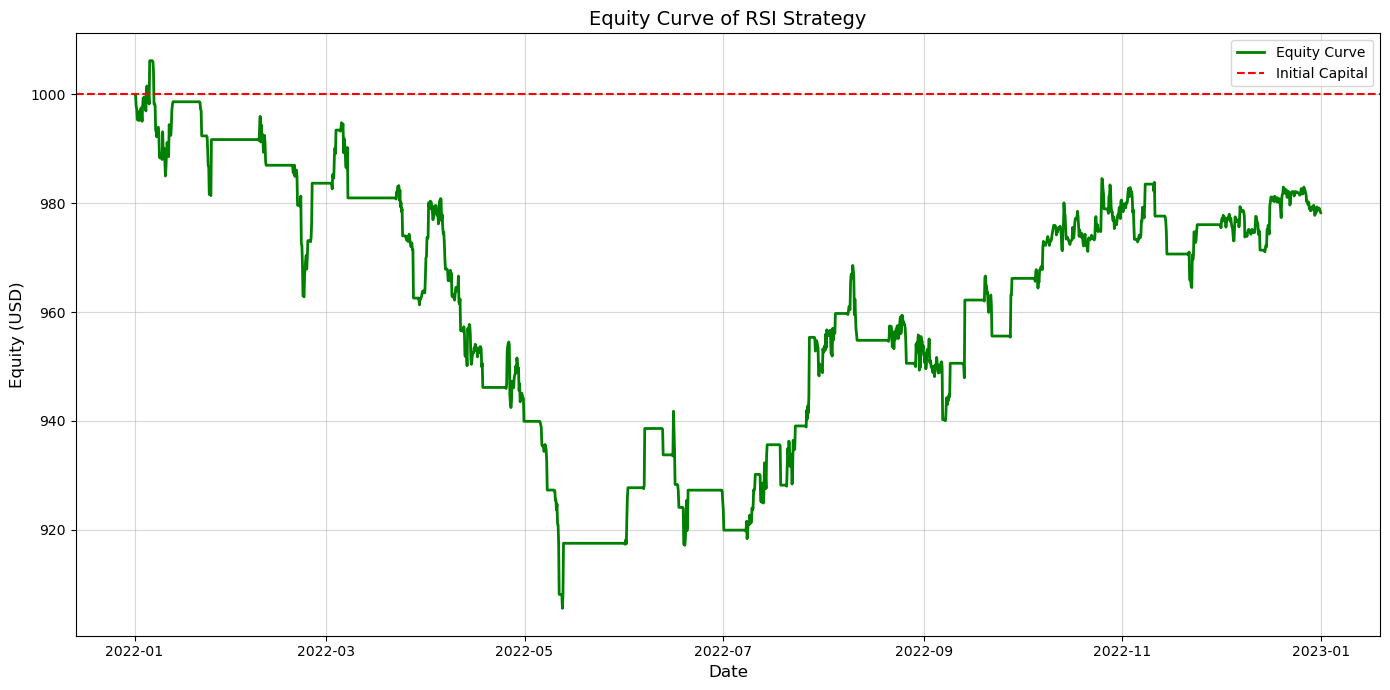

In [57]:
rsi_strategy = RSI(src)
price = "Close"
rsi_strategy.add_rsi(price=price, window=14)
rsi_strategy.trade(price=price, margin_portion=0.2)
rsi_strategy.report()

In [10]:
rsi_strategy.trades_info

,position-type,entry-date,entry-price,exit-date,exit-price,reason,trade-return,account-impact
0,short,2022-01-01 04:00:00,46711.05,2022-01-01 17:00:00,47754.48,Meeting Loss Level,-2.436031,-0.487206
1,short,2022-01-01 18:00:00,47560.55,2022-01-03 20:00:00,45922.00,Cross Oversold level,3.248632,0.646561
2,long,2022-01-03 21:00:00,45979.01,2022-01-05 19:00:00,44685.93,Meeting Loss Level,-3.009514,-0.602862
3,long,2022-01-06 12:00:00,43062.76,2022-01-07 03:00:00,41803.11,Meeting Loss Level,-3.122224,-0.621675
4,long,2022-01-07 07:00:00,41706.71,2022-01-08 17:00:00,40842.12,Meeting Loss Level,-2.270951,-0.449352
...,...,...,...,...,...,...,...,...
147,short,2022-12-13 17:00:00,17643.73,2022-12-14 14:00:00,18062.07,Meeting Loss Level,-2.573412,-0.461180
148,short,2022-12-14 19:00:00,17792.90,2022-12-15 22:00:00,17339.91,Cross Oversold level,2.348449,0.418698
149,long,2022-12-15 23:00:00,17356.34,2022-12-16 10:00:00,16994.06,Meeting Loss Level,-2.285219,-0.409339
150,long,2022-12-16 14:00:00,17029.59,2022-12-16 23:00:00,16632.12,Meeting Loss Level,-2.531662,-0.451410


In [11]:
rsi_strategy.statistics

{'initial-capital': 1000,
 'capital': 884.7952201121132,
 'tp': 0.05,
 'sl': 0.02,
 'commission-rate': 0.001,
 'commission-paid': 56.23937384214611,
 'win-rate': 35.526315789473685,
 'total-trade': 152,
 'winning-trade': 54,
 'losing-trade': 98,
 'breakeven-trade': 0,
 'total-return': -11.520477988788684,
 'rsi': 'RSI-Close-14',
 'rsi-window': 14,
 'oversold-level': 30,
 'overbought-level': 70}

# 4- Donchian Channels Strategy

✨ Start Trading ....
✅ Trading Finished Successfully.
===================  Final Backtest Result of Donchian Channel Strategy ===================
❇️ Initial Capital: 1000.00 USD
❇️ Final Capital: 1033.27 USD
❇️ Profit-Loss: 33.27 USD
❇️ Total Return: 3.33 %
❇️ Total Trades: 66 (Winning: 26 | Losing: 40)
❇️ Win-Rate: 39.39 %


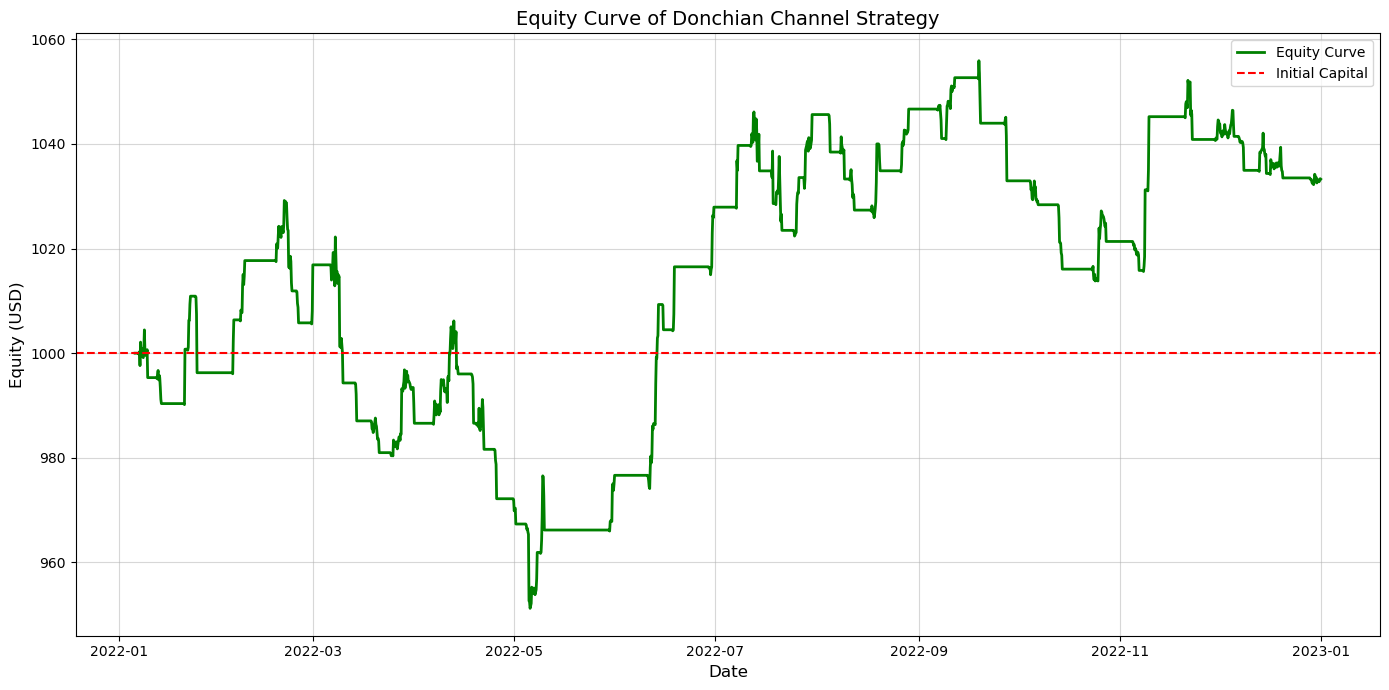

In [58]:
channel_strategy = DonchianChannel(src)
window = 30
channel_strategy.add_channels(window=window)
channel_strategy.trade(window=window, margin_portion=0.2)
channel_strategy.report()

In [3]:
channel_strategy.trades_info

,position-type,entry-date,entry-price,exit-date,exit-price,reason,trade-return,account-impact
0,short,2022-01-03 16:00:00,46482.34,2022-01-04 11:00:00,46733.77,Upward Middle Channel Cross,-0.741456,-0.148291
1,short,2022-01-05 19:00:00,44685.93,2022-01-07 03:00:00,41803.11,Meeting Profit Level,6.257744,1.249693
2,long,2022-01-09 19:00:00,42695.26,2022-01-10 00:00:00,41655.18,Meeting Loss Level,-2.633619,-0.532525
3,short,2022-01-10 12:00:00,40930.00,2022-01-10 16:00:00,41904.40,Meeting Loss Level,-2.583031,-0.519545
4,long,2022-01-11 16:00:00,42705.24,2022-01-13 15:00:00,43200.00,Downward Middle Channel Cross,0.957388,0.191572
...,...,...,...,...,...,...,...,...
221,short,2022-12-22 14:00:00,16675.03,2022-12-22 20:00:00,16781.42,Upward Middle Channel Cross,-0.838658,-0.151683
222,long,2022-12-26 02:00:00,16889.69,2022-12-26 15:00:00,16809.51,Downward Middle Channel Cross,-0.674253,-0.121744
223,short,2022-12-27 14:00:00,16772.25,2022-12-28 14:00:00,16739.01,Upward Middle Channel Cross,-0.001617,-0.000292
224,short,2022-12-28 21:00:00,16527.88,2022-12-29 14:00:00,16629.53,Upward Middle Channel Cross,-0.815636,-0.147073


In [4]:
channel_strategy.statistics

{'initial-capital': 1000,
 'capital': 898.8759782014967,
 'tp': 0.05,
 'sl': 0.02,
 'commission-rate': 0.001,
 'commission-paid': 85.0897753805175,
 'win-rate': 31.41592920353982,
 'total-trade': 226,
 'winning-trade': 71,
 'losing-trade': 155,
 'breakeven-trade': 0,
 'total-return': -10.112402179850335,
 'window': 30}

# 5- MACD Strategy

✨ Start Trading ....
✅ Trading Finished Successfully.
===================  Final Backtest Result of MACD Strategy ===================
❇️ Initial Capital: 1000.00 USD
❇️ Final Capital: 825.43 USD
❇️ Profit-Loss: -174.57 USD
❇️ Total Return: -17.46 %
❇️ Total Trades: 106 (Winning: 27 | Losing: 79)
❇️ Win-Rate: 25.47 %


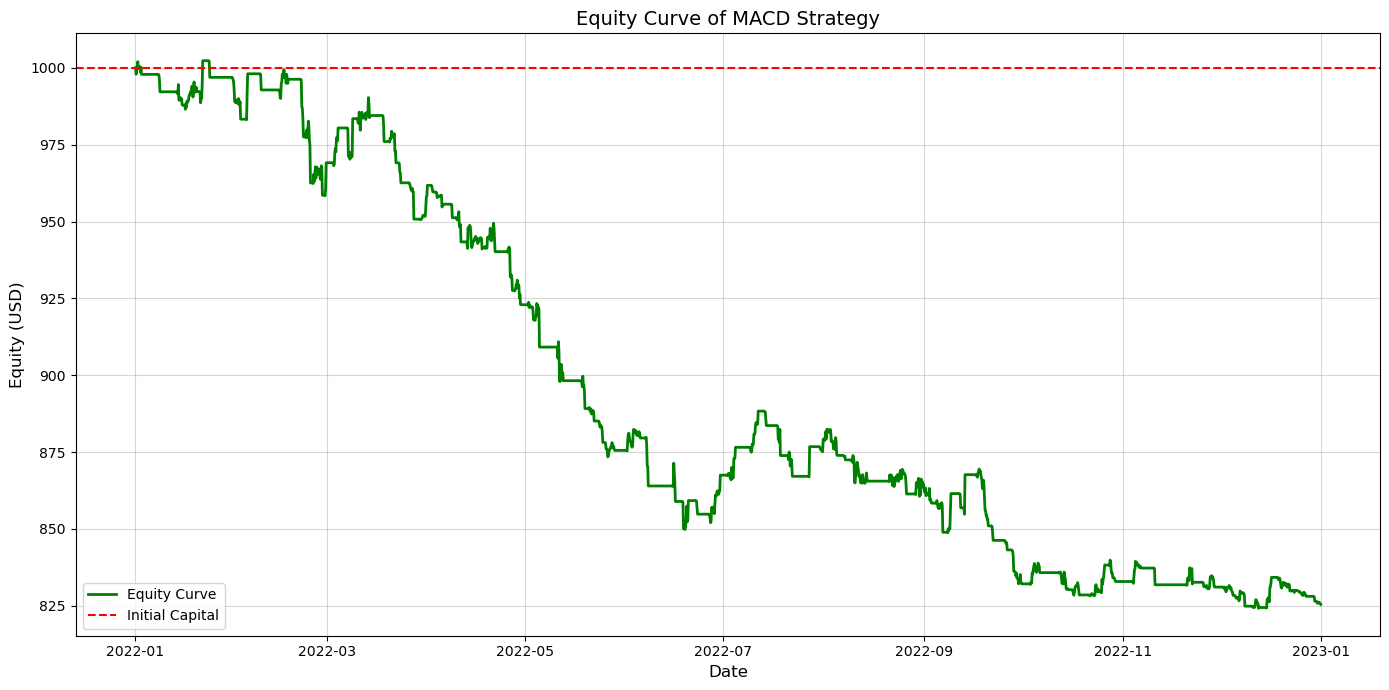

In [59]:
macd_strategy = MACD(src)
macd_strategy.trade(margin_portion=0.2)
macd_strategy.report()

In [4]:
macd_strategy.trades_info

,position-type,entry-date,entry-price,exit-date,exit-price,reason,trade-return,account-impact
0,long,2022-01-01 01:00:00,46778.14,2022-01-01 14:00:00,46926.22,Downward MACD Cross,0.116242,0.023248
1,long,2022-01-01 15:00:00,47219.04,2022-01-02 02:00:00,47370.50,Downward MACD Cross,0.120440,0.024094
2,long,2022-01-02 16:00:00,47792.30,2022-01-02 18:00:00,47058.12,Downward MACD Cross,-1.734653,-0.347095
3,long,2022-01-03 10:00:00,47126.02,2022-01-03 15:00:00,46693.45,Downward MACD Cross,-1.116983,-0.222727
4,long,2022-01-04 06:00:00,46367.53,2022-01-04 18:00:00,45750.00,Downward MACD Cross,-1.530484,-0.304497
...,...,...,...,...,...,...,...,...
362,short,2022-12-27 08:00:00,16849.22,2022-12-28 09:00:00,16659.00,Upward MACD Cross,0.930083,0.164740
363,short,2022-12-28 21:00:00,16527.88,2022-12-29 04:00:00,16572.23,Upward MACD Cross,-0.468603,-0.083155
364,short,2022-12-30 05:00:00,16554.39,2022-12-30 17:00:00,16533.12,Upward MACD Cross,-0.071386,-0.012656
365,short,2022-12-31 09:00:00,16544.26,2022-12-31 10:00:00,16566.03,Upward MACD Cross,-0.331718,-0.058801


In [5]:
macd_strategy.statistics

{'initial-capital': 1000,
 'capital': 885.7817342089045,
 'tp': 0.05,
 'sl': 0.02,
 'commission-rate': 0.001,
 'commission-paid': 134.05089544381593,
 'win-rate': 30.79019073569482,
 'total-trade': 367,
 'winning-trade': 113,
 'losing-trade': 254,
 'breakeven-trade': 0,
 'total-return': -11.421826579109553,
 'fast ema': 12,
 'slow ema': 26,
 'signal ema': 9}

# 6- Hybrid Strategy (RSI + MACD + EMA)

✨ Start Trading ....
✅ Trading Finished Successfully.
===================  Final Backtest Result of RSI MACD EMA Strategy ===================
❇️ Initial Capital: 1000.00 USD
❇️ Final Capital: 893.16 USD
❇️ Profit-Loss: -106.84 USD
❇️ Total Return: -10.68 %
❇️ Total Trades: 78 (Winning: 23 | Losing: 55)
❇️ Win-Rate: 29.49 %


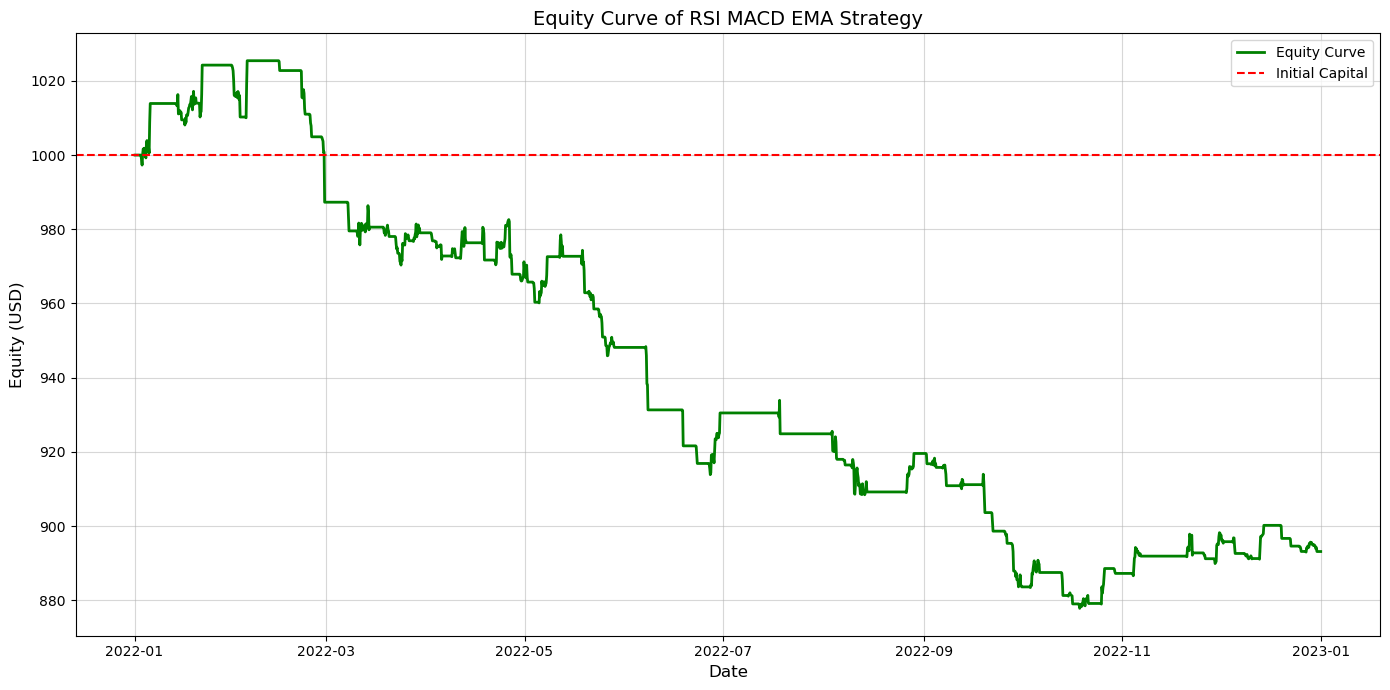

In [60]:
hybrid_strategy = RsiMacdEma(src)
hybrid_strategy.trade(margin_portion=0.2)
hybrid_strategy.report()

In [11]:
hybrid_strategy.trades_info

,position-type,entry-date,entry-price,exit-date,exit-price,reason,trade-return,account-impact
0,short,2022-01-19,41660.01,2022-01-29,38166.84,Upward MACD Cross,8.193333,1.638667
1,short,2022-02-18,39974.44,2022-02-28,43160.00,Meeting Loss Level,-8.176961,-1.662191
2,short,2022-03-06,38420.81,2022-03-09,41941.71,Meeting Loss Level,-9.373208,-1.874201
3,long,2022-03-16,41114.00,2022-04-05,45497.55,Downward MACD Cross,10.451278,2.050588
4,short,2022-05-05,36552.97,2022-05-11,29103.94,Meeting Profit Level,20.199106,4.045997
5,short,2022-06-12,26574.53,2022-06-16,20401.31,Meeting Profit Level,23.053067,4.804207
6,long,2022-08-08,23810.00,2022-08-17,23342.66,Downward MACD Cross,-2.160826,-0.471073
7,short,2022-09-18,19416.18,2022-09-28,19412.82,Upward MACD Cross,-0.182678,-0.039653
8,short,2022-10-12,19155.53,2022-10-13,19375.13,Upward MACD Cross,-1.347552,-0.292398
9,short,2022-10-15,19069.39,2022-10-16,19262.98,Upward MACD Cross,-1.216202,-0.263186


In [12]:
hybrid_strategy.statistics

{'initial-capital': 1000,
 'capital': 1093.3898644529424,
 'tp': 0.2,
 'sl': 0.07,
 'commission-rate': 0.001,
 'commission-paid': 5.39797843909043,
 'win-rate': 38.46153846153847,
 'total-trade': 13,
 'winning-trade': 5,
 'losing-trade': 8,
 'breakeven-trade': 0,
 'total-return': 9.338986445294244,
 'fast ema': 12,
 'slow ema': 26,
 'signal ema': 9,
 'rsi window': 14,
 'rsi threshold': 50,
 'trend ema': 50}